# LLM Profiling Framework MVP — Notebook

Mục tiêu: đo riêng **Prefill**, **Decode**, latency, throughput và các chỉ số bộ nhớ trên MacBook Apple Silicon. Chạy từ trên xuống dưới.

> Lưu ý: `sshleifer/tiny-gpt2` chỉ để kiểm thử pipeline; số đo không đại diện cho LLM lớn. MPS là backend của Apple, không phải CUDA/NVIDIA.

## 1. Cài đặt (chạy một lần trong Terminal)

Từ thư mục gốc dự án, kích hoạt `.venv` rồi chạy `pip install -e .`. Sau đó mở notebook bằng `jupyter notebook notebooks/llm_profiling_mvp.ipynb`.

In [1]:
from pathlib import Path
import sys, platform
import pandas as pd
import matplotlib.pyplot as plt

# Nếu kernel chưa dùng đúng virtualenv, hãy chọn kernel của .venv trong Jupyter.
print("Python:", sys.version)
print("Platform:", platform.platform())


Python: 3.12.11 (main, Jun  3 2025, 15:41:47) [Clang 17.0.0 (clang-1700.0.13.3)]
Platform: macOS-26.6.2-arm64-arm-64bit


## 2. Cấu hình thí nghiệm

In [2]:
from profiling_mvp.benchmark import RunConfig, benchmark, choose_device
import torch

DEVICE = "auto"       # "auto", "mps", or "cpu"
MODEL = "sshleifer/tiny-gpt2"
PROMPT_TOKENS = 64
NEW_TOKENS = 32
REPEATS = 3
WARMUP = 1
OUTPUT_DIR = "results/notebook"

device = choose_device(DEVICE)
print("Selected device:", device)
print("MPS available:", torch.backends.mps.is_available() if hasattr(torch.backends, "mps") else False)


Selected device: mps
MPS available: True


## 3. Chạy benchmark

In [3]:
config = RunConfig(
    model=MODEL,
    device=DEVICE,
    prompt_tokens=PROMPT_TOKENS,
    max_new_tokens=NEW_TOKENS,
    repeats=REPEATS,
    warmup=WARMUP,
    seed=1234,
    output_dir=OUTPUT_DIR,
)
runs, metadata = benchmark(config)
df = pd.DataFrame(runs)
display(df)
print("\nEnvironment:")
display(pd.Series(metadata["environment"]).to_frame("value"))


Loading tokenizer/model: sshleifer/tiny-gpt2


Loading weights:   0%|          | 0/29 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: sshleifer/tiny-gpt2
Key                                   | Status     |  | 
--------------------------------------+------------+--+-
transformer.h.{0, 1}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device=mps; prompt target=64; new tokens=32
Warm-up 1/1
Run 1/3: prefill=0.0081s, decode=0.0968s, decode_tps=320.36, RSS=529.8MB
Run 2/3: prefill=0.0049s, decode=0.0653s, decode_tps=474.89, RSS=529.9MB
Run 3/3: prefill=0.0062s, decode=0.0789s, decode_tps=393.14, RSS=530.0MB

Saved:
  results/notebook/benchmark-20261012-001138-p64-n32.csv
  results/notebook/benchmark-20261012-001138-p64-n32.json


,prefill_latency_s,decode_latency_s,decode_step_latency_mean_s,decode_step_latency_p50_s,end_to_end_model_time_s,generated_tokens,decode_tokens_timed,decode_tokens_per_s,end_to_end_tokens_per_s,prompt_tokens_actual,process_rss_mb,torch_allocated_mb,torch_reserved_or_driver_mb,run_index,model,device,prompt_tokens_requested,max_new_tokens_requested,seed
0,0.008058,0.096767,0.003122,0.002825,0.104825,32,31,320.356044,305.269233,64,529.844,0.41,1037.125,1,sshleifer/tiny-gpt2,mps,64,32,1234
1,0.004909,0.065278,0.002106,0.001984,0.070187,32,31,474.889259,455.924336,64,529.859,0.41,1037.125,2,sshleifer/tiny-gpt2,mps,64,32,1234
2,0.006160,0.078853,0.002544,0.002589,0.085013,32,31,393.138686,376.412847,64,530.000,0.41,1037.125,3,sshleifer/tiny-gpt2,mps,64,32,1234



Environment:


,value
python,3.12.11
platform,macOS-26.6.2-arm64-arm-64bit
machine,arm64
torch_version,2.14.1
transformers_version,5.19.0
device,mps
mps_available,True
cuda_available,False


## 4. Tóm tắt kết quả

In [4]:
metrics = [
    "prefill_latency_s",
    "decode_latency_s",
    "decode_step_latency_mean_s",
    "decode_tokens_per_s",
    "end_to_end_model_time_s",
    "process_rss_mb",
]
summary = df[metrics].agg(["median", "mean", "std"]).T
display(summary)


,median,mean,std
prefill_latency_s,0.006160,0.006376,0.001586
decode_latency_s,0.078853,0.080299,0.015794
decode_step_latency_mean_s,0.002544,0.002590,0.000509
decode_tokens_per_s,393.138686,396.127996,77.309964
end_to_end_model_time_s,0.085013,0.086675,0.017379
process_rss_mb,529.859000,529.901000,0.086064


## 5. Biểu đồ latency và throughput

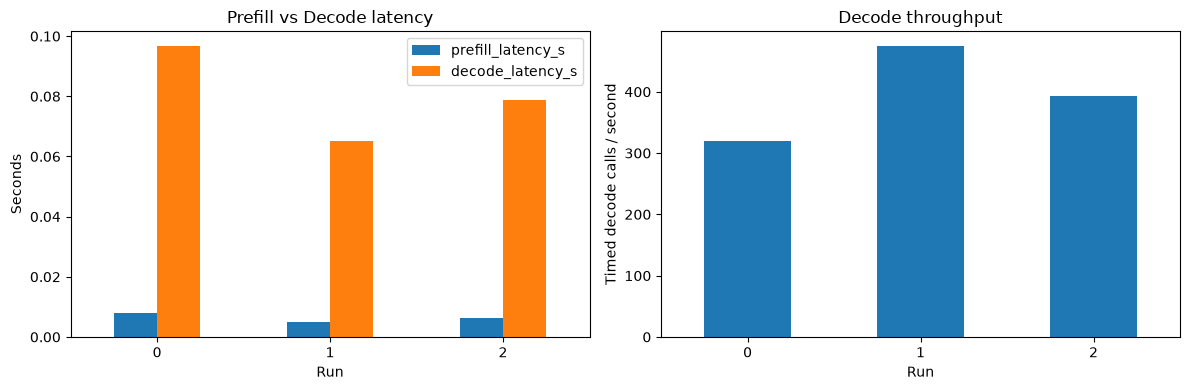

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df[["prefill_latency_s", "decode_latency_s"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Prefill vs Decode latency")
axes[0].set_ylabel("Seconds")
axes[0].set_xlabel("Run")
axes[0].tick_params(axis="x", rotation=0)

df["decode_tokens_per_s"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Decode throughput")
axes[1].set_ylabel("Timed decode calls / second")
axes[1].set_xlabel("Run")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


## 6. Thí nghiệm A — ảnh hưởng của độ dài prompt

Chỉ thay đổi `prompt_tokens`; giữ nguyên model, device, số token sinh, warm-up và số lần lặp. Mặc định dưới đây dùng các giá trị nhỏ để chạy nhanh.

In [6]:
prompt_lengths = [32, 64, 128]
experiment_rows = []

for length in prompt_lengths:
    cfg = RunConfig(
        model=MODEL, device=DEVICE, prompt_tokens=length,
        max_new_tokens=16, repeats=REPEATS, warmup=WARMUP,
        seed=1234, output_dir=f"results/notebook_prompt_{length}"
    )
    exp_runs, _ = benchmark(cfg)
    for row in exp_runs:
        experiment_rows.append(row)

prompt_df = pd.DataFrame(experiment_rows)
prompt_summary = prompt_df.groupby("prompt_tokens_requested").agg(
    prefill_median_s=("prefill_latency_s", "median"),
    decode_median_s=("decode_latency_s", "median"),
    decode_tps_median=("decode_tokens_per_s", "median"),
    rss_median_mb=("process_rss_mb", "median"),
).reset_index()
display(prompt_summary)


Loading tokenizer/model: sshleifer/tiny-gpt2


Loading weights:   0%|          | 0/29 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: sshleifer/tiny-gpt2
Key                                   | Status     |  | 
--------------------------------------+------------+--+-
transformer.h.{0, 1}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device=mps; prompt target=32; new tokens=16
Warm-up 1/1
Run 1/3: prefill=0.0036s, decode=0.0376s, decode_tps=398.52, RSS=557.6MB
Run 2/3: prefill=0.0043s, decode=0.0334s, decode_tps=449.50, RSS=557.6MB
Run 3/3: prefill=0.0039s, decode=0.0353s, decode_tps=425.22, RSS=557.6MB

Saved:
  results/notebook_prompt_32/benchmark-20261012-001141-p32-n16.csv
  results/notebook_prompt_32/benchmark-20261012-001141-p32-n16.json
Loading tokenizer/model: sshleifer/tiny-gpt2


Loading weights:   0%|          | 0/29 [00:00<?, ?it/s]

...

Device=mps; prompt target=64; new tokens=16
Warm-up 1/1
Run 1/3: prefill=0.0043s, decode=0.0396s, decode_tps=378.49, RSS=555.8MB
Run 2/3: prefill=0.0050s, decode=0.0419s, decode_tps=358.39, RSS=555.8MB
Run 3/3: prefill=0.0058s, decode=0.0426s, decode_tps=352.16, RSS=555.8MB

Saved:
  results/notebook_prompt_64/benchmark-20261012-001143-p64-n16.csv
  results/notebook_prompt_64/benchmark-20261012-001143-p64-n16.json
Loading tokenizer/model: sshleifer/tiny-gpt2


Loading weights:   0%|          | 0/29 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: sshleifer/tiny-gpt2
Key                                   | Status     |  | 
--------------------------------------+------------+--+-
transformer.h.{0, 1}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device=mps; prompt target=128; new tokens=16
Warm-up 1/1
Run 1/3: prefill=0.0053s, decode=0.0449s, decode_tps=333.83, RSS=561.2MB
Run 2/3: prefill=0.0064s, decode=0.0481s, decode_tps=311.67, RSS=561.2MB
Run 3/3: prefill=0.0065s, decode=0.0505s, decode_tps=296.86, RSS=561.2MB

Saved:
  results/notebook_prompt_128/benchmark-20261012-001146-p128-n16.csv
  results/notebook_prompt_128/benchmark-20261012-001146-p128-n16.json


,prompt_tokens_requested,prefill_median_s,decode_median_s,decode_tps_median,rss_median_mb
0,32,0.003899,0.035276,425.217243,557.625
1,64,0.005021,0.041854,358.388701,555.797
2,128,0.006442,0.048128,311.671598,561.219


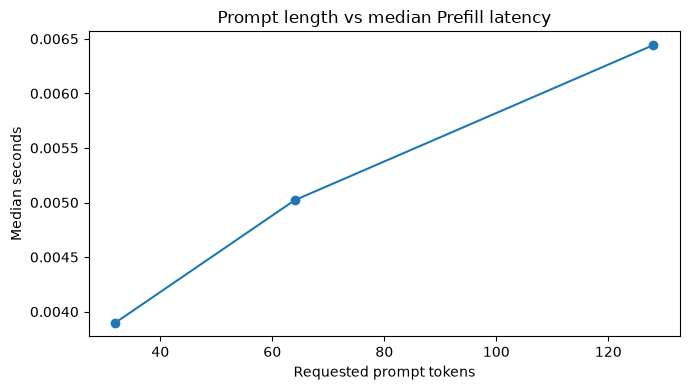

In [7]:
ax = prompt_summary.plot(
    x="prompt_tokens_requested", y="prefill_median_s",
    marker="o", legend=False, figsize=(7, 4)
)
ax.set_title("Prompt length vs median Prefill latency")
ax.set_xlabel("Requested prompt tokens")
ax.set_ylabel("Median seconds")
plt.tight_layout()
plt.show()


## 7. Thí nghiệm B — ảnh hưởng của số token sinh

Chỉ thay đổi số token được sinh. Decode latency sẽ tăng theo số bước decode; throughput có thể thay đổi do chi phí cố định và độ dài chuỗi.

In [8]:
generation_lengths = [8, 16, 32]
generation_rows = []

for length in generation_lengths:
    cfg = RunConfig(
        model=MODEL, device=DEVICE, prompt_tokens=64,
        max_new_tokens=length, repeats=REPEATS, warmup=WARMUP,
        seed=1234, output_dir=f"results/notebook_new_{length}"
    )
    exp_runs, _ = benchmark(cfg)
    for row in exp_runs:
        generation_rows.append(row)

gen_df = pd.DataFrame(generation_rows)
gen_summary = gen_df.groupby("max_new_tokens_requested").agg(
    decode_median_s=("decode_latency_s", "median"),
    decode_tps_median=("decode_tokens_per_s", "median"),
    e2e_median_s=("end_to_end_model_time_s", "median"),
    rss_median_mb=("process_rss_mb", "median"),
).reset_index()
display(gen_summary)


Loading tokenizer/model: sshleifer/tiny-gpt2


Loading weights:   0%|          | 0/29 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: sshleifer/tiny-gpt2
Key                                   | Status     |  | 
--------------------------------------+------------+--+-
transformer.h.{0, 1}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device=mps; prompt target=64; new tokens=8
Warm-up 1/1
Run 1/3: prefill=0.0044s, decode=0.0207s, decode_tps=338.52, RSS=562.3MB
Run 2/3: prefill=0.0047s, decode=0.0232s, decode_tps=302.17, RSS=562.3MB
Run 3/3: prefill=0.0055s, decode=0.0190s, decode_tps=367.79, RSS=562.3MB

Saved:
  results/notebook_new_8/benchmark-20261012-001148-p64-n8.csv
  results/notebook_new_8/benchmark-20261012-001148-p64-n8.json
Loading tokenizer/model: sshleifer/tiny-gpt2


Loading weights:   0%|          | 0/29 [00:00<?, ?it/s]

...

Device=mps; prompt target=64; new tokens=16
Warm-up 1/1
Run 1/3: prefill=0.0053s, decode=0.0360s, decode_tps=416.51, RSS=562.4MB
Run 2/3: prefill=0.0069s, decode=0.0384s, decode_tps=390.14, RSS=562.4MB
Run 3/3: prefill=0.0053s, decode=0.0461s, decode_tps=325.73, RSS=562.1MB

Saved:
  results/notebook_new_16/benchmark-20261012-001150-p64-n16.csv
  results/notebook_new_16/benchmark-20261012-001150-p64-n16.json
Loading tokenizer/model: sshleifer/tiny-gpt2


Loading weights:   0%|          | 0/29 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: sshleifer/tiny-gpt2
Key                                   | Status     |  | 
--------------------------------------+------------+--+-
transformer.h.{0, 1}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device=mps; prompt target=64; new tokens=32
Warm-up 1/1
Run 1/3: prefill=0.0046s, decode=0.0629s, decode_tps=493.08, RSS=564.2MB
Run 2/3: prefill=0.0043s, decode=0.0652s, decode_tps=475.54, RSS=564.2MB
Run 3/3: prefill=0.0050s, decode=0.0620s, decode_tps=499.80, RSS=564.2MB

Saved:
  results/notebook_new_32/benchmark-20261012-001153-p64-n32.csv
  results/notebook_new_32/benchmark-20261012-001153-p64-n32.json


,max_new_tokens_requested,decode_median_s,decode_tps_median,e2e_median_s,rss_median_mb
0,8,0.020678,338.524036,0.025031,562.344
1,16,0.038448,390.136495,0.045340,562.375
2,32,0.062870,493.081283,0.067433,564.219


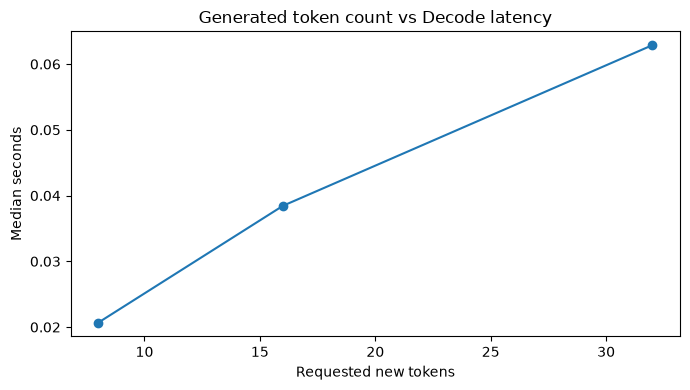

In [9]:
ax = gen_summary.plot(
    x="max_new_tokens_requested", y="decode_median_s",
    marker="o", legend=False, figsize=(7, 4)
)
ax.set_title("Generated token count vs Decode latency")
ax.set_xlabel("Requested new tokens")
ax.set_ylabel("Median seconds")
plt.tight_layout()
plt.show()


## 8. Diễn giải và liên hệ nghiên cứu

- **Prefill:** xử lý toàn bộ prompt ở một forward pass; do đó prompt length là biến thí nghiệm trực tiếp.
- **Decode:** mỗi bước tiếp tục từ token mới nhất và dùng KV cache; số token sinh là biến ảnh hưởng trực tiếp đến tổng decode time.
- **Latency / throughput:** latency đo thời gian; throughput đo lượng công việc hoàn thành trong một đơn vị thời gian. Không nên suy ra throughput chỉ từ một lần chạy.
- **Memory:** RSS là bộ nhớ resident của toàn bộ tiến trình Python. Các số allocator của PyTorch chỉ có khi backend hỗ trợ và không phải tổng RAM vật lý mà GPU/SoC sử dụng.
- **Liên hệ bài báo:** phương pháp tách pha và thay đổi có kiểm soát các biến mô phỏng cách tiếp cận systematic characterization. Trên Mac MPS, ta không thể khẳng định kết luận về CUDA kernel hoặc L2 cache của GPU NVIDIA.
- **Hạn chế:** timing không gồm tokenization/model loading; decode loop là bản minh họa không tối ưu; profiler overhead chưa được trộn vào benchmark nền.

### Câu hỏi nên trả lời trong báo cáo
1. Prefill latency thay đổi ra sao khi prompt dài hơn?
2. Decode latency thay đổi ra sao khi yêu cầu sinh nhiều token hơn?
3. Throughput có ổn định giữa các lần chạy không? Vì sao?
4. Chỉ số RSS có thể dùng làm đại diện cho bộ nhớ mô hình chính xác đến mức nào?
5. Kết luận nào chỉ đúng trên máy Mac đang thử nghiệm, và kết luận nào cần GPU NVIDIA để xác minh?